# 03 · Harness: list, then count

Counting small symbols on dense CAD plans is where models slip. The harness asks the model to **scan the plan region by region and list every matching symbol with its location before giving the number** (for presence questions: scan, then answer). Then the same prompt with **5 samples at temperature 0.7 and a majority vote**.

- `glm_enum`: list-then-count prompt
- `glm_enum_vote`: list-then-count, majority of 5

Baseline: GLM 5.3 Flash with the plain prompt.

In [1]:
import asyncio, json, os, sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "fp_common.py").exists():
    HERE = Path("experiments/floorplancad-symbol-counting").resolve()
os.chdir(HERE)
sys.path.insert(0, str(HERE))

import fp_common as f
import fp_report as rep
rep.fv.apply_theme()
print(f.build(), "· API key set:", bool(os.getenv("FIREWORKS_API_KEY")))

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 6219, 'test': 1000} · API key set: True


In [2]:
ENUM = ("\nMethod: scan the plan in a 3×3 grid (top-left to bottom-right). For each region, list every matching symbol "
        "you see with a few words on where it is. Count partial symbols cut by the edge of the plan only if most of the symbol is visible. "
        "Then give the total (or yes/no) on the last line.")
def enum_messages(r):
    msgs = f.messages(r)
    msgs[0] = {"role": "system", "content": f.SYSTEM + ENUM}
    return msgs

## Run · ≈$0.50 for one sample, ≈$2.50 for five

In [3]:
await f.eval_model("glm", "glm_enum", build_messages=enum_messages)
await f.eval_model("glm", "glm_enum_vote", build_messages=enum_messages, n=5, temperature=0.7)

glm_enum: GLM 5.3 Flash on test · n=1 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

glm_enum: accuracy 62.3% · counting exact 42.6%, within ±1 72.9% (n=1000)
glm_enum_vote: GLM 5.3 Flash on test · n=5 · to_run=0


images: 0it [00:00, ?it/s]

images: 0it [00:00, ?it/s]

glm_enum_vote: accuracy 64.4% · counting exact 45.1%, within ±1 74.3% (n=1000)


## Results vs the plain GLM baseline

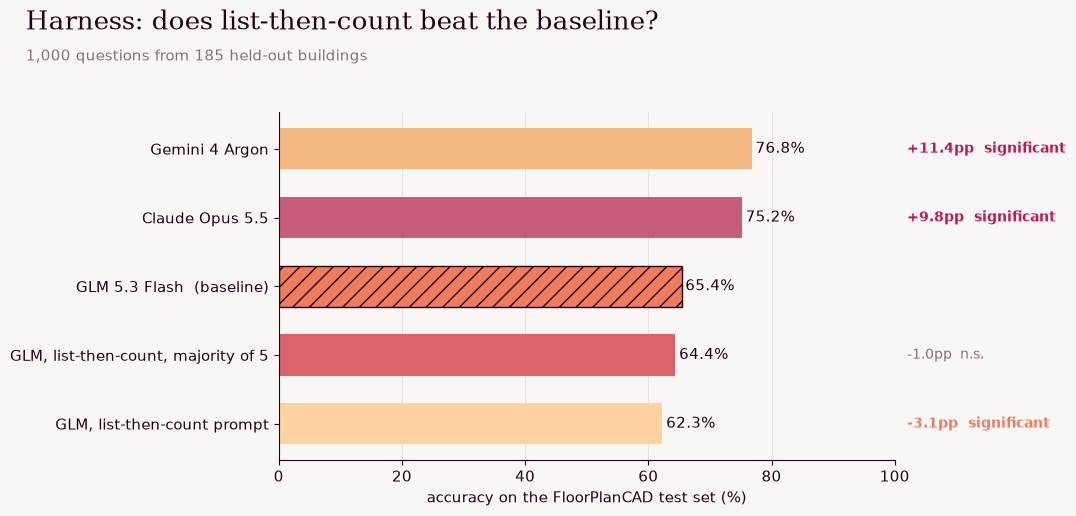

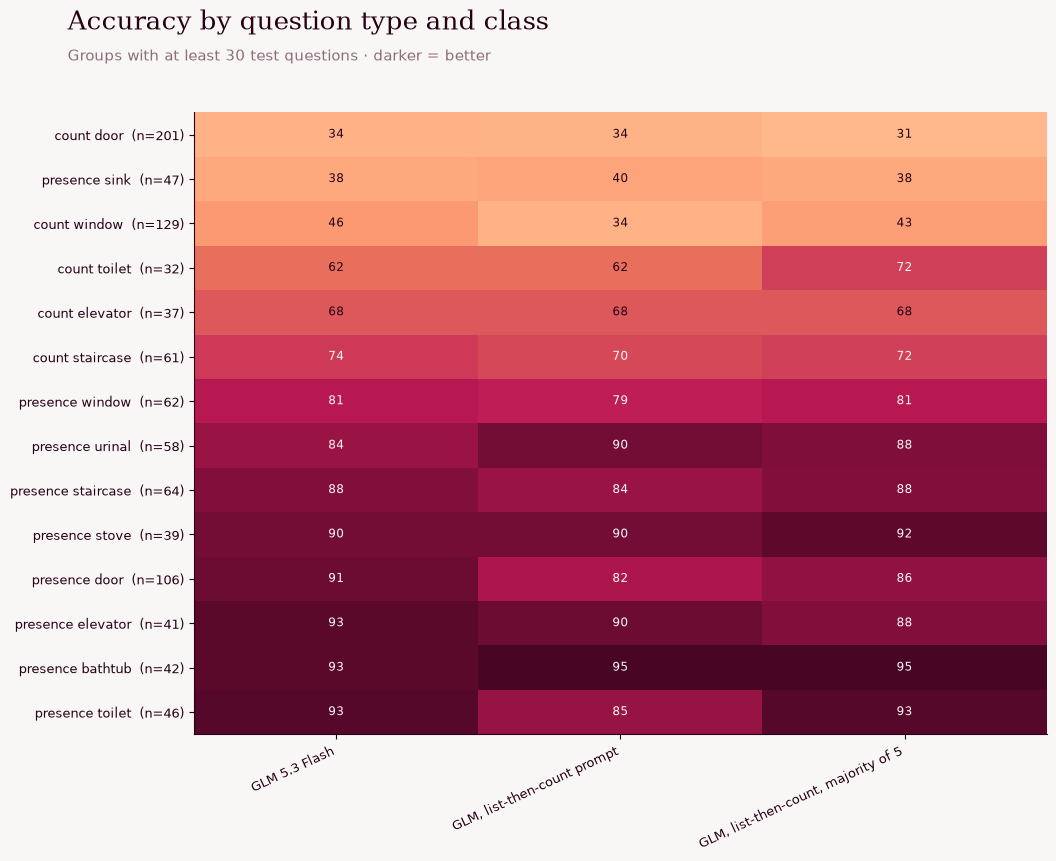

,n,acc_a,acc_b,Δpp,only_a,only_b,McNemar p,boot 95% CI,significant,notes
pair,,,,,,,,,,
"GLM, list-then-count prompt vs GLM 5.3 Flash",1000,62.3%,65.4%,-3.1,59,90,0.0137,"[-5.5, -0.7]",True,loss holds under both tests
"GLM, list-then-count, majority of 5 vs GLM 5.3 Flash",1000,64.4%,65.4%,-1.0,59,69,0.4264,"[-3.1, +1.1]",False,within noise


,n,acc_a,acc_b,Δpp,only_a,only_b,McNemar p,boot 95% CI,significant,notes
pair,,,,,,,,,,
"GLM, list-then-count prompt vs GLM 5.3 Flash",1000,62.3%,65.4%,-3.1,59,90,0.0137,"[-5.5, -0.7]",True,loss holds under both tests
"GLM, list-then-count, majority of 5 vs GLM 5.3 Flash",1000,64.4%,65.4%,-1.0,59,69,0.4264,"[-3.1, +1.1]",False,within noise


In [4]:
rep.leaderboard(["glm", "glm_enum", "glm_enum_vote", "gemini4", "opus55"], "glm",
                "Harness: does list-then-count beat the baseline?", "1,000 questions from 185 held-out buildings")
rep.class_heatmap(["glm", "glm_enum", "glm_enum_vote"])
rep.significance_table([("glm_enum", "glm"), ("glm_enum_vote", "glm")])

**Stats.** McNemar on paired right/wrong per question, plus a bootstrap that resamples whole *buildings* (tiles from one building are correlated). A gain counts only when both are significant.